In [1]:
import sys
sys.path.append("../")

from problems.testfuncs import Quadratic, Rosenbrock2d, RosenbrockNd, Himmelblau, make_quadratic
from optlib.utils import grad_check

import numpy as np

SEED=0
rng = np.random.default_rng(SEED)


# 1.1 - 1.2 Test funcs and grad verification

In [2]:
def verifyQuadratic():
    n = 32
    
    # define A such that symmetric and positive definite 
    M = rng.random((n,n), dtype=np.float64)
    A = M.T @ M + n * np.eye(n)
    b = rng.random(n, dtype=np.float64)
    x = rng.random(n, dtype=np.float64)
    
    f = Quadratic(A, b)
    grad = f.grad(x)
    errors = grad_check(f, x, grad, n=8)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [3]:
def verifyRosenbrock2d():
    a, b = rng.random(), rng.random()
    f = Rosenbrock2d(a, b)
    x, y = rng.random(), rng.random()
    x = np.array([x,y])
    grad = f.grad(x)
    errors = grad_check(f, x, np.array(grad), n=2)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [4]:
def verifyRosenbrockNd():
    N=32
    f = RosenbrockNd()
    x = rng.random(N)
    
    grad = f.grad(x)
    errors = grad_check(f, x, grad, n=8)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [5]:
def verifyHimmelblau():
    N=2
    f = Himmelblau()
    x = rng.random(N)
    
    grad = f.grad(x)
    errors = grad_check(f, x, grad, n=2)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [6]:
verifyQuadratic()
verifyRosenbrock2d()
verifyRosenbrockNd()
verifyHimmelblau()

# 1.3 Steepest GD

In [7]:
n=32*32
A_k1    = make_quadratic(n, kappa=1);    assert(np.isclose(np.linalg.cond(A_k1), 1))
A_k10   = make_quadratic(n, kappa=10);   assert(np.isclose(np.linalg.cond(A_k10), 10))
A_k100  = make_quadratic(n, kappa=100);  assert(np.isclose(np.linalg.cond(A_k100), 100))
A_k1000 = make_quadratic(n, kappa=1000); assert(np.isclose(np.linalg.cond(A_k1000), 1000))
A_ks = [A_k1, A_k10, A_k100, A_k1000]

In [8]:
from optlib.first_order import GD

results = []
x0=rng.random(n)
for A, kappa in zip(A_ks, (1,10,100,1000)):
    f = Quadratic(A=A, b=np.zeros(n))
    eigvals = np.linalg.eigvalsh(A)
    step = 2.0 / (eigvals[-1] + eigvals[0])
    # step = 1 / eigvals[-1]
    qcgd = GD(step)
    res = qcgd.minimize(f, x0, tol=1e-8, max_iter=10000)
    results.append(res)
    print(f"CONVERGED?: {res.converged}")
    

CONVERGED?: True
CONVERGED?: True
CONVERGED?: True
CONVERGED?: False


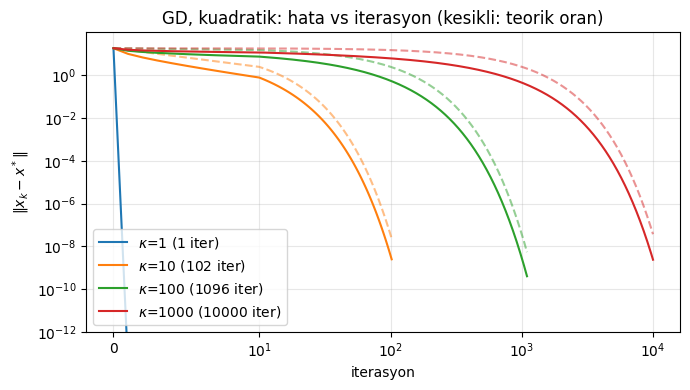

In [9]:
import matplotlib.pyplot as plt

kappas = (1, 10, 100, 1000)
error_list = []
x_star = np.zeros(x0.shape[0]) # b=0 olduğu için global çözüm x_star=0
for res in results:
    errors = np.array([np.linalg.norm(xk - x_star) for xk in res.history["x"]])
    error_list.append(errors)

fig, ax = plt.subplots(figsize=(7, 4))
for err, kappa in zip(error_list, kappas):
    line, = ax.semilogy(err, label=fr"$\kappa$={kappa} ({err.size-1} iter)")
    # teorik sınır: e_k <= r^k e_0, r = (k-1)/(k+1)
    if kappa > 1:
        k = np.arange(err.size)
        ax.semilogy(k, err[0] * ((kappa-1)/(kappa+1))**k, "--", color=line.get_color(), alpha=0.5)
ax.set_xscale("symlog", linthresh=10)
ax.set_ylim(bottom=1e-12)
ax.set_xlabel("iterasyon")
ax.set_ylabel(r"$\|x_k - x^*\|$")
ax.set_title("GD, kuadratik: hata vs iterasyon (kesikli: teorik oran)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [10]:
for err in error_list:
    print(err.shape)

(2,)
(103,)
(1097,)
(10001,)


In [11]:
def calc_r(k):
    return (k-1)/(k+1)

def fit_r(errors, lo_frac=0.2, hi_frac=1.0):
    e = np.asarray(errors, dtype=float)

    # 1) önce sadece sonlu ve kesin pozitif olanları al
    ok = np.isfinite(e) & (e > 0)
    if ok.sum() < 5:
        return np.nan

    e0 = e[ok][0]
    # 2) makine tabanını e0'a göre ele
    ok &= e > 1e-13 * e0

    k = np.arange(e.size)
    idx = np.flatnonzero(ok)
    lo = idx[int(lo_frac * idx.size)]
    hi = idx[min(int(hi_frac * idx.size), idx.size - 1)]

    m = ok.copy()
    m[:lo] = False
    m[hi+1:] = False

    if m.sum() < 5:
        return np.nan

    y = np.log(e[m])
    if not np.all(np.isfinite(y)):          # son savunma
        return np.nan

    slope = np.polyfit(k[m], y, 1)[0]
    return np.exp(slope)
    
slope = [calc_r(10), calc_r(100), calc_r(1000)]
r_expr = [] 

for err in error_list:
    if err.size > 30:
        r = fit_r(err)
        r_expr.append(float(r))

print(slope)
print(r_expr)

[0.8181818181818182, 0.9801980198019802, 0.998001998001998]
[0.8109309248317572, 0.9794173778889282, 0.9979166904959443]


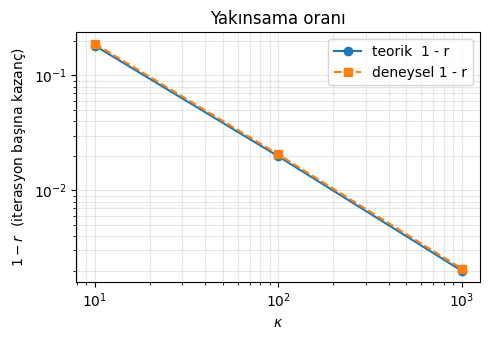

In [12]:
# deneysel vs teorik yakınsama oranı
fig, ax = plt.subplots(figsize=(5, 3.5))
ks = np.array([10, 100, 1000])
ax.plot(ks, 1 - np.array(slope), "o-", label="teorik  1 - r")
ax.plot(ks, 1 - np.array(r_expr), "s--", label="deneysel 1 - r")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\kappa$")
ax.set_ylabel(r"$1 - r$  (iterasyon başına kazanç)")
ax.set_title("Yakınsama oranı")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# 1.4 Backtracking Line Search

In [13]:
from optlib.line_search import BacktrackingLineSearch

rosen = Rosenbrock2d(a=1, b=100)
bls = BacktrackingLineSearch(rho=0.5, c=1e-4, alpha0=1.0)
x0 = np.array([-1.2, 1.0])
res_bls = bls.minimize(rosen, x0=x0.copy(), tol=1e-6, max_iter=20000, warm_start=True)

print(f"Bactracking LS n_iter: {res_bls.n_iter}")
print(f"CONVERGED: {res_bls.converged}")

Bactracking LS n_iter: 15110
CONVERGED: True


In [14]:
alpha_set = [1e-2, 1e-3, 1e-4, 1e-5]
res_gd = []  
for alpha in alpha_set:
    gd = GD(alpha)
    res = gd.minimize(rosen, x0.copy(), tol=1e-6, max_iter=100000)
    res_gd.append(res)

/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:36: RuntimeWarning: overflow encountered in scalar power
  return (a - x)**2 + b*(y - x**2)**2
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:41: RuntimeWarning: overflow encountered in scalar power
  return np.array([(-2 * (a - x)) + (2 * b*(y - x**2) * (-2*x)),
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:42: RuntimeWarning: overflow encountered in scalar power
  2 * b*(y - x**2)])
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:36: RuntimeWarning: invalid value encountered in scalar subtract
  return (a - x)**2 + b*(y - x**2)**2
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:41: RuntimeWarning: invalid value encountered in scalar subtract
  return np.array([(-2 * (a - x)) + (2 * b*(y - x**2) * (-2*x)),
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  2 * b*(y - x**2)])


GD alpha=0.01: ıraksadı (6. iterasyonda inf/nan)


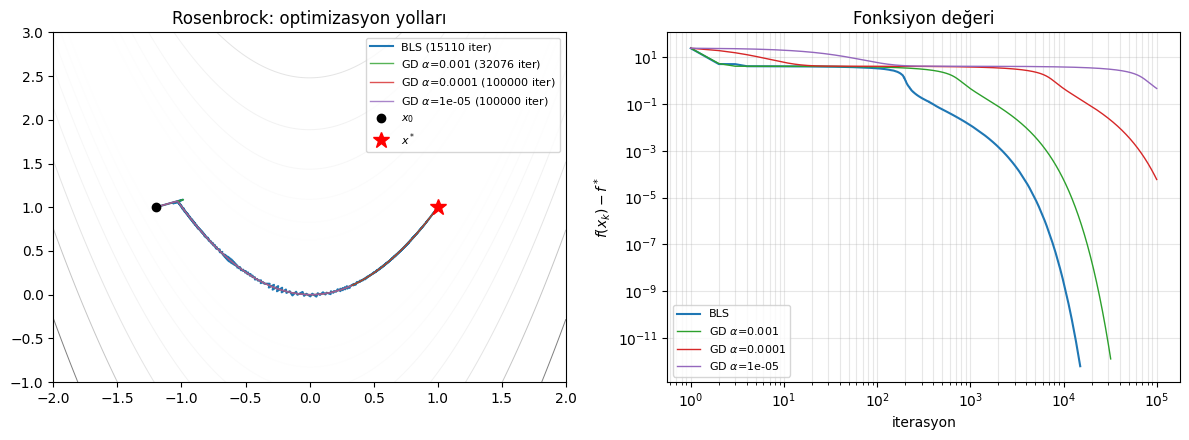

In [15]:
# Rosenbrock kontur üzerinde yollar
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

X, Y = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
Z = (1 - X)**2 + 100*(Y - X**2)**2
ax1.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 20), cmap="Greys", linewidths=0.7)

def plot_path(ax, res, label, **kw):
    P = np.array(res.history["x"])
    P = P[np.all(np.isfinite(P), axis=1) & np.all(np.abs(P) < 5, axis=1)]
    ax.plot(P[:, 0], P[:, 1], label=label, **kw)

colors = {a: f"C{i+1}" for i, a in enumerate(alpha_set)}
plot_path(ax1, res_bls, f"BLS ({res_bls.n_iter} iter)", lw=1.5, color="C0")
for alpha, res in zip(alpha_set, res_gd):
    if res.converged or np.isfinite(res.fval):
        plot_path(ax1, res, fr"GD $\alpha$={alpha:g} ({res.n_iter} iter)", lw=1, alpha=0.8, color=colors[alpha])
ax1.plot(*x0, "ko", label="$x_0$")
ax1.plot(1, 1, "r*", ms=12, label="$x^*$")
ax1.set_xlim(-2, 2); ax1.set_ylim(-1, 3)
ax1.set_title("Rosenbrock: optimizasyon yolları")
ax1.legend(fontsize=8)

# f(x_k) - f* vs iterasyon
ax2.loglog(np.arange(1, len(res_bls.history["f"])+1), res_bls.history["f"], label="BLS", lw=1.5, color="C0")
for alpha, res in zip(alpha_set, res_gd):
    fh = np.asarray(res.history["f"], dtype=float)
    if np.all(np.isfinite(fh)):
        ax2.loglog(np.arange(1, fh.size+1), fh, label=fr"GD $\alpha$={alpha:g}", lw=1, color=colors[alpha])
    else:
        print(f"GD alpha={alpha:g}: ıraksadı ({np.argmax(~np.isfinite(fh))}. iterasyonda inf/nan)")
ax2.set_xlabel("iterasyon")
ax2.set_ylabel(r"$f(x_k) - f^*$")
ax2.set_title("Fonksiyon değeri")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

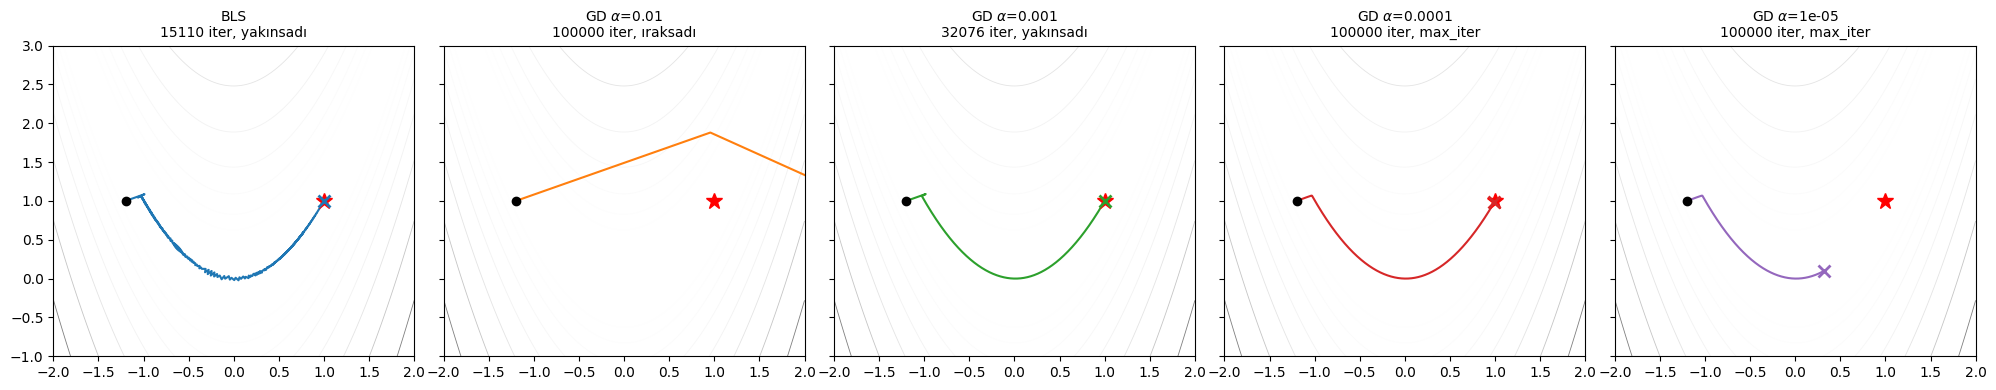

In [16]:
# her metodun yörüngesi ayrı panelde
runs = [("BLS", res_bls, "C0")] + [(fr"GD $\alpha$={a:g}", r, colors[a]) for a, r in zip(alpha_set, res_gd)]

fig, axes = plt.subplots(1, len(runs), figsize=(4 * len(runs), 4), sharex=True, sharey=True)
for ax, (name, res, color) in zip(axes, runs):
    ax.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 20), cmap="Greys", linewidths=0.6)
    plot_path(ax, res, None, lw=1.5, color=color)
    ax.plot(*x0, "ko")
    ax.plot(1, 1, "r*", ms=12)
    if np.all(np.isfinite(res.x)):
        ax.plot(*res.x, "x", color=color, ms=9, mew=2)
        status = "yakınsadı" if res.converged else "max_iter"
    else:
        status = "ıraksadı"
    ax.set_title(f"{name}\n{res.n_iter} iter, {status}", fontsize=10)
    ax.set_xlim(-2, 2); ax.set_ylim(-1, 3)
fig.tight_layout()
plt.show()

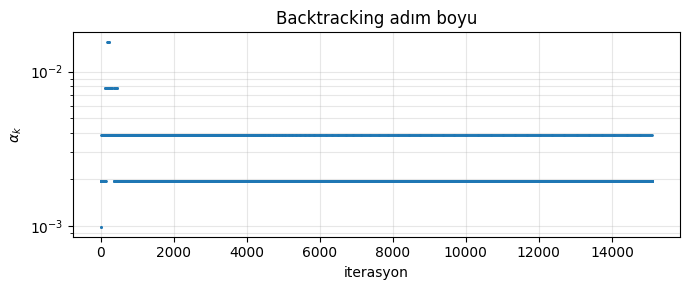

In [17]:
# BLS'nin seçtiği adım boyları
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(res_bls.history["step"], ".", ms=2)
ax.set_xlabel("iterasyon")
ax.set_ylabel(r"$\alpha_k$")
ax.set_title("Backtracking adım boyu")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

# 1.5 Momentum & Nesterov Acceleration 